<a href="https://colab.research.google.com/github/julybar2004-afk/DataXperience/blob/main/Analisis_Alojamientos_Bogota.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Proyecto Final - Ciencia de Datos

## 🏙️ Análisis de Precios de Alojamientos en Bogotá

### 👥 Integrantes

- Paula Andrea Amador Barrios
- Julian David Barbosa Duarte
- Brenda Jeritza Gómez Espitia

---

## 🎯 Objetivo

Analizar los factores que influyen en el precio de los alojamientos turísticos en Bogotá mediante técnicas de limpieza de datos, estadística descriptiva y modelado predictivo.

---

## 🌎 Contexto del Proyecto

La creciente oferta de alojamientos turísticos en Bogotá genera una amplia diversidad de precios y características. Este proyecto busca aplicar herramientas de Ciencia de Datos para identificar patrones, comprender el comportamiento de los precios y analizar los factores que pueden influir en su variación.

A través de procesos de exploración, limpieza, análisis estadístico, visualización de datos y modelado predictivo, se pretende obtener información relevante que contribuya a la comprensión del mercado de alojamientos turísticos y a la toma de decisiones basada en datos.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#  ETAPA 1 - Fundamentos y Preparación de Datos

## 📚 Importación de Librerías

Se importan las librerías necesarias para la manipulación, análisis y visualización de datos.

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

**📂 Carga del Dataset**

Se carga el archivo CSV y se realiza una revisión inicial de la estructura de los datos.

In [47]:
from google.colab import files

uploaded = files.upload()

Saving Data.csv to Data (1).csv


In [48]:
df = pd.read_csv("Data.csv")

df.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,27841,Rosales Luxury Large 2BR Boutique Apt,113734,1462509905126026119,Marcela,NaN,Chapinero,4.657580,-74.053260,Entire home/apt,274831.0,28.0,45,2025-09-14,0.23,3,168,0,112727.0
1,65762,Apartaestudios La Candelaria,321447,1462515641808590179,Teresa,NaN,Candelaria,4.594850,-74.071890,Entire home/apt,215000.0,1.0,33,2025-04-28,0.19,24,258,0,100613.0
2,124029,Exclusive Loft in 93 park w Gym,619048,1462513052712343807,Jaime,NaN,Chapinero,4.679779,-74.055817,Entire home/apt,278843.0,10.0,53,2024-12-21,0.28,2,289,0,69770.0
3,130427,Feel like home @ nice & new loft,642197,1462524657755403478,Jaime,NaN,Suba,4.695060,-74.061650,Entire home/apt,215380.0,30.0,2,2011-10-14,0.01,1,365,0,NaN
4,138660,Excelent Studio ROSALES/ ZONA G,676823,1462513470872353935,Carlos,NaN,Chapinero,4.648440,-74.055270,Entire home/apt,76361.0,30.0,22,2018-10-21,0.14,1,225,0,NaN


**🔍 Exploración Inicial**

Se realiza una exploración inicial del conjunto de datos para identificar la cantidad de registros, variables y tipos de datos presentes.

In [49]:
df.info()#nos indica informacion de los datos como clase del objeto, valores nulos, etc
df.shape#nos indica el tamaño del dataset en formato(filas,columnas)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19505 entries, 0 to 19504
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              19505 non-null  int64  
 1   name                            19505 non-null  object 
 2   host_id                         19505 non-null  int64  
 3   host_profile_id                 19505 non-null  int64  
 4   host_name                       19505 non-null  object 
 5   neighbourhood_group             0 non-null      float64
 6   neighbourhood                   19505 non-null  object 
 7   latitude                        19505 non-null  float64
 8   longitude                       19505 non-null  float64
 9   room_type                       19505 non-null  object 
 10  price                           18794 non-null  float64
 11  minimum_nights                  19498 non-null  float64
 12  number_of_reviews               

(19505, 19)

**📌 Resultado**

El conjunto de datos está compuesto por 19.505 registros y 19 variables relacionadas con alojamientos turísticos en Bogotá.

**⚠️ Identificación de Valores Faltantes**

Se revisó la presencia de valores faltantes con el fin de evaluar la calidad de la información y determinar posibles estrategias de tratamiento.

In [50]:
print(df.isnull().sum()) #/len(df) #con len nos mostraria el porcentaje de valores nulos

id                                    0
name                                  0
host_id                               0
host_profile_id                       0
host_name                             0
neighbourhood_group               19505
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                               711
minimum_nights                        7
number_of_reviews                     0
last_review                        4089
reviews_per_month                  4089
calculated_host_listings_count        0
availability_365                      0
number_of_reviews_ltm                 0
license                            2942
dtype: int64


**✅ Verificación de Registros Nulos o Faltantes**

Se verificó la existencia de registros nulos para evitar sesgos en los análisis estadísticos y predictivos.





**⚠️ Identificación de Valores Duplicados**

Se revisó la presencia de valores duplicados con el fin de evaluar la calidad de la información y determinar posibles estrategias de tratamiento.

In [51]:
df.duplicated().sum()

np.int64(0)

**📌 Resultado**

No se encontraron registros duplicados.

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19505 entries, 0 to 19504
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              19505 non-null  int64  
 1   name                            19505 non-null  object 
 2   host_id                         19505 non-null  int64  
 3   host_profile_id                 19505 non-null  int64  
 4   host_name                       19505 non-null  object 
 5   neighbourhood_group             0 non-null      float64
 6   neighbourhood                   19505 non-null  object 
 7   latitude                        19505 non-null  float64
 8   longitude                       19505 non-null  float64
 9   room_type                       19505 non-null  object 
 10  price                           18794 non-null  float64
 11  minimum_nights                  19498 non-null  float64
 12  number_of_reviews               

El conjunto de datos está compuesto por 19.505 registros y 19 variables relacionadas con alojamientos turísticos en Bogotá, incluyendo información sobre ubicación, tipo de alojamiento, precio, disponibilidad y reseñas de los usuarios.

**📋 Variables Relevantes para el Estudio**

* id
* name
* host_id
* host_name
* neighbourhood
* room_type
* price
* number_of_reviews
* reviews_per_month
* license
* minimum_nights
* availability_365
* last_review




# **Limpieza de Datos**

**Eliminación de la variable neighbourhood_group y aquellas variables que no usaremos**

La variable neighbourhood_group presenta un 100% de valores faltantes, por lo que no aporta información útil al análisis y se elimina del conjunto de datos. Las demas varibles no las usaremos en este analisis por lo cual tambien seran eliminadas





In [53]:
df.drop(columns=["neighbourhood_group","longitude","latitude","host_profile_id","license"], inplace=True)
df.head()

,id,name,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm
0,27841,Rosales Luxury Large 2BR Boutique Apt,113734,Marcela,Chapinero,Entire home/apt,274831.0,28.0,45,2025-09-14,0.23,3,168,0
1,65762,Apartaestudios La Candelaria,321447,Teresa,Candelaria,Entire home/apt,215000.0,1.0,33,2025-04-28,0.19,24,258,0
2,124029,Exclusive Loft in 93 park w Gym,619048,Jaime,Chapinero,Entire home/apt,278843.0,10.0,53,2024-12-21,0.28,2,289,0
3,130427,Feel like home @ nice & new loft,642197,Jaime,Suba,Entire home/apt,215380.0,30.0,2,2011-10-14,0.01,1,365,0
4,138660,Excelent Studio ROSALES/ ZONA G,676823,Carlos,Chapinero,Entire home/apt,76361.0,30.0,22,2018-10-21,0.14,1,225,0


**Manejo de registros sin precio**

Se identificaron 711 registros con precio faltante. Debido a que el precio es la variable principal del estudio, estos registros serán eliminados para evitar la distorcion de los datos.

In [54]:
df = df.dropna(subset=["price"])
print("Valores nulos restantes en 'price':", df['price'].isnull().sum())

Valores nulos restantes en 'price': 0


**Manejo de registros sin minimum_nights**:


La variable minimum_nights presenta únicamente 7 valores faltantes, por lo que su impacto sobre el análisis es mínimo por lo cual, eliminaremos esta columma

In [55]:
df = df.dropna(subset=["minimum_nights"])
print("Valores nulos restantes en 'minimum_nights':", df['minimum_nights'].isnull().sum())

Valores nulos restantes en 'minimum_nights': 0


**Tratamiento de reviews_per_month**

Los valores faltantes en la variable reviews_per_month pueden corresponder a alojamientos que aún no han recibido evaluaciones. Por esta razón, la información se conserva.

In [56]:
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)
df.head(10)

,id,name,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm
0,27841,Rosales Luxury Large 2BR Boutique Apt,113734,Marcela,Chapinero,Entire home/apt,274831.0,28.0,45,2025-09-14,0.23,3,168,0
1,65762,Apartaestudios La Candelaria,321447,Teresa,Candelaria,Entire home/apt,215000.0,1.0,33,2025-04-28,0.19,24,258,0
2,124029,Exclusive Loft in 93 park w Gym,619048,Jaime,Chapinero,Entire home/apt,278843.0,10.0,53,2024-12-21,0.28,2,289,0
3,130427,Feel like home @ nice & new loft,642197,Jaime,Suba,Entire home/apt,215380.0,30.0,2,2011-10-14,0.01,1,365,0
4,138660,Excelent Studio ROSALES/ ZONA G,676823,Carlos,Chapinero,Entire home/apt,76361.0,30.0,22,2018-10-21,0.14,1,225,0
5,142658,"Amazing view and location, Bogotá!",1113082,Ximena,Santa Fe,Entire home/apt,143134.0,30.0,9,2016-08-10,0.05,1,70,0
7,162316,ROOM IN LUXURIOUS DUPLEX APARTMENT,775844,Victoria,Barrios Unidos,Private room,106610.0,3.0,49,2025-11-08,0.28,2,264,2
8,178850,"MODERN APARTMENT, 3 ROOMS, 4 PAX",498646,Irma,Usaquen,Entire home/apt,167408.0,30.0,3,2019-12-01,0.03,2,365,0
9,207283,L MODERNO APARTAESTUDIO LOFT CHAPINERO,1019554,Yaqueline,Chapinero,Entire home/apt,169000.0,1.0,57,2025-01-14,0.40,7,361,0
10,210785,Confortable bedroom Private Room in Bogota No. 1,1017332,Edgar Hernán,Fontibon,Private room,127994.0,2.0,7,2013-05-01,0.04,3,292,0


In [57]:
df.isnull().sum()

,0
id,0
name,0
host_id,0
host_name,0
neighbourhood,0
room_type,0
price,0
minimum_nights,0
number_of_reviews,0
last_review,3783


**📌 Resumen de la Limpieza**

Durante la fase de exploración se identificaron valores faltantes en varias variables. Se eliminaron las columnas que no aportaban valor al análisis y se trataron los registros faltantes para garantizar una mejor calidad de los datos.

In [58]:
df.describe()

,id,host_id,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm
count,1.878700e+04,1.878700e+04,1.878700e+04,18787.000000,18787.000000,18787.000000,18787.000000,18787.000000,18787.000000
mean,1.002494e+18,3.432407e+16,2.929341e+05,6.496407,29.139990,1.195066,13.597807,306.732368,10.002449
std,6.149653e+17,2.408852e+17,3.850037e+06,11.331006,59.371564,1.901312,24.720958,82.989469,18.859906
min,2.784100e+04,2.516700e+04,1.540200e+04,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,6.324931e+17,1.039609e+08,1.098200e+05,1.000000,1.000000,0.060000,1.000000,269.000000,0.000000
50%,1.173891e+18,2.766665e+08,1.607720e+05,1.000000,9.000000,0.530000,4.000000,348.000000,3.000000
75%,1.522581e+18,5.026565e+08,2.295570e+05,3.000000,34.000000,1.630000,13.000000,361.000000,13.000000
max,1.774233e+18,1.772701e+18,2.585147e+08,360.000000,2586.000000,45.690000,151.000000,365.000000,609.000000


In [59]:
df.duplicated().sum()

np.int64(0)

# 📈 ETAPA 2 - Estadística Descriptiva y Preprocesamiento

🎯 Objetivo

Comprender el comportamiento de los alojamientos turísticos mediante medidas estadísticas y visualizaciones.

**📊 Medidas de Tendencia Central**

In [60]:
print(f"Media: {df["price"].mean()}")
print(f"Mediana: { df["price"].median()}")
print(f"Moda:, {df["price"].mode()}")

Media: 292934.05046042474
Mediana: 160772.0
Moda:, 0    120000.0
1    180000.0
Name: price, dtype: float64


**📌 Interpretación**

* Media: $292.934

* Mediana: $160.772

* Moda: $120.000 y $180.000

La diferencia entre la media y la mediana indica la presencia de alojamientos con precios elevados que aumentan el promedio general.

**📉 Medidas de Dispersión**

In [61]:
print("Rango:", df["price"].max() - df["price"].min())
print("Varianza:", df["price"].var())
print("Desviación estándar:", df["price"].std())

Rango: 258499276.0
Varianza: 14822785616081.404
Desviación estándar: 3850037.0928188995


**📌 Interpretación**

La desviación estándar muestra una alta dispersión en los precios, evidenciando una amplia variedad de ofertas.

**📊 Histograma de Precios**

registros originales 18787
registros tras eliminar valores atípicos 18619
porcentaje de datos conservados 99.11%


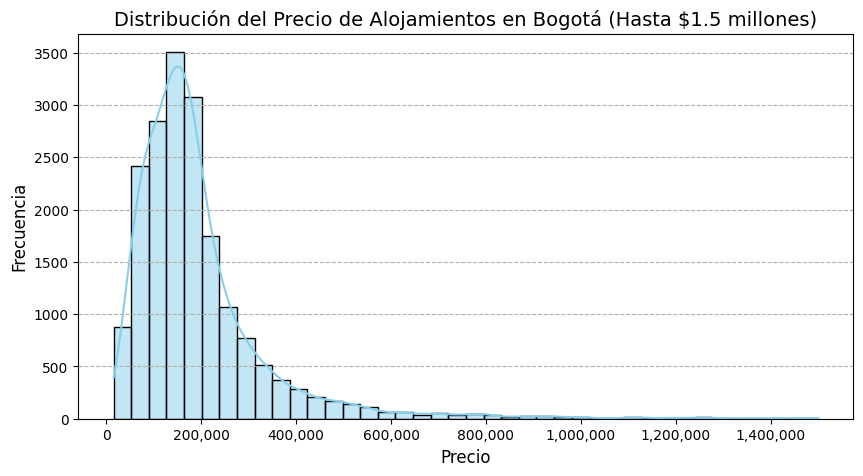

In [62]:
plt.figure(figsize=(10,5))

#se crea un nuevo dataset para evitar una grafica afectada por los outliers
limite_precio_superior = 1500000
df_filtrado = df[df['price'] <= limite_precio_superior].copy()
print(f"registros originales {len(df)}")
print(f"registros tras eliminar valores atípicos {len(df_filtrado)}")
print(f"porcentaje de datos conservados {round(len(df_filtrado) / len(df) * 100, 2)}%")

#histograma
sns.histplot(df_filtrado["price"], bins=40, kde=True ,color="skyblue", edgecolor="black")
plt.title("Distribución del Precio de Alojamientos en Bogotá (Hasta $1.5 millones)", fontsize=14)
plt.xlabel("Precio", fontsize=12)
plt.ylabel("Frecuencia", fontsize=12)
plt.grid(axis='y', linestyle='--')
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))


#sns.histplot(df["price"], bins=30)

#plt.title("Distribución de precios de alojamientos en Bogotá")
#plt.xlabel("Precio")
#plt.ylabel("Frecuencia")
plt.show()



**📌 Interpretación**

La mayor concentración de alojamientos se encuentra en rangos de precios bajos y medios.

**📊 Identificación de Valores Atípicos**

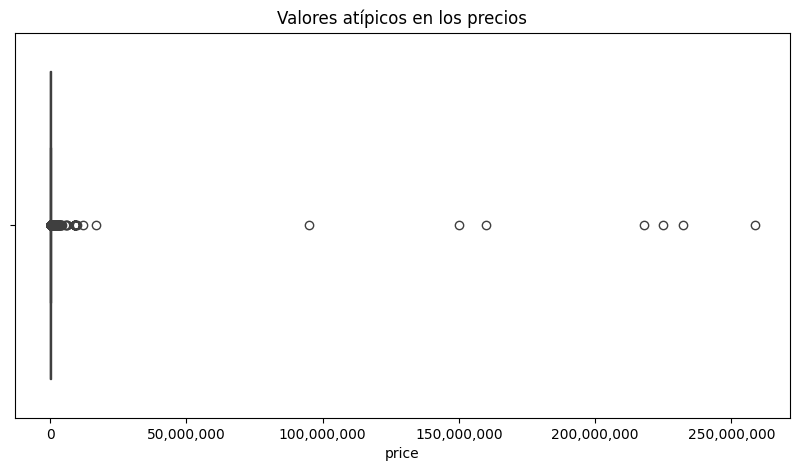

In [63]:
plt.figure(figsize=(10,5))

sns.boxplot(x=df["price"])

plt.title("Valores atípicos en los precios")
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))
plt.show()

**📌 Interpretación**

Se observan valores atípicos que pueden influir en los resultados estadísticos.

**📊 Comparación de Precios por Tipo de Alojamiento**

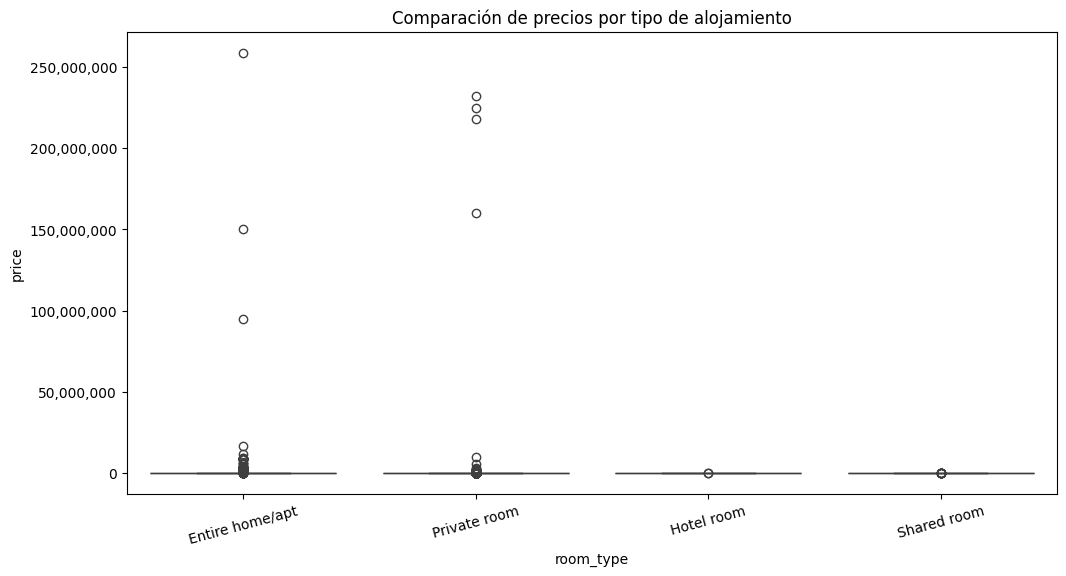

In [64]:
plt.figure(figsize=(12,6))

sns.boxplot(data=df, x="room_type", y="price")

plt.xticks(rotation=15)

plt.title("Comparación de precios por tipo de alojamiento")
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))
plt.show()

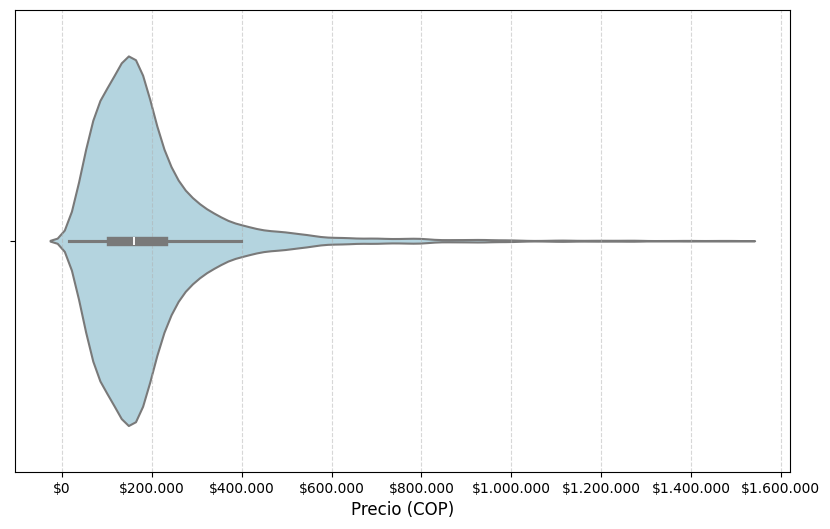

In [65]:
plt.figure(figsize=(10, 6))

# Usamos el dataframe filtrado para evitar que los valores atípicos de millones distorsionen el gráfico
sns.violinplot(data=df_filtrado, x="price", color="lightblue", inner="box", linewidth=1.5)

# Personalización y títulos profesionales
#plt.title("Dispersión y Densidad del Precio de los Alojamientos (Hasta $1.5M COP)", fontsize=14, pad=15)
plt.xlabel("Precio (COP)", fontsize=12)

# Añadimos cuadrícula interna para facilitar la lectura
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Formateamos el eje X con puntos como separadores de miles
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"${int(x):,}".replace(',', '.')))

#plt.tight_layout()
plt.show()

**📌 Interpretación**

Los alojamientos completos presentan precios más altos que las habitaciones privadas y compartidas.



**📊 Matriz de Correlación**

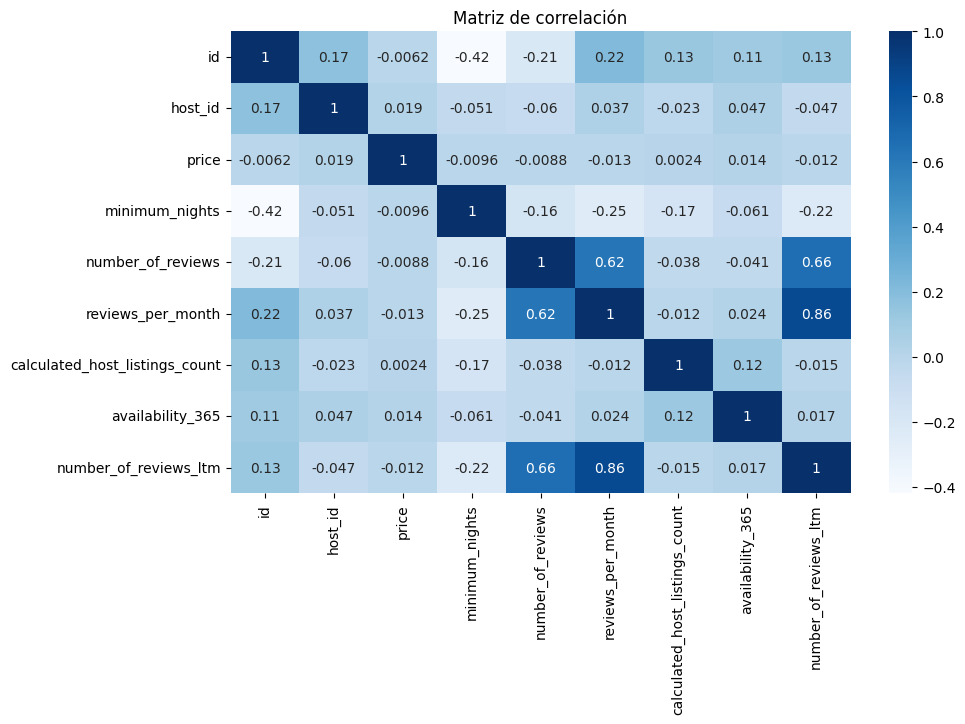

In [66]:
plt.figure(figsize=(10,6))

correlacion = df.select_dtypes(include=['int64','float64']).corr()

sns.heatmap(correlacion, annot=True, cmap="Blues")

plt.title("Matriz de correlación")
plt.show()

**📌 Interpretación**

Permite identificar posibles relaciones entre las variables numéricas.


In [67]:
df["room_type"].value_counts()

,count
room_type,
Entire home/apt,13651
Private room,4990
Shared room,119
Hotel room,27


In [68]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood', 'room_type',
       'price', 'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365', 'number_of_reviews_ltm'],
      dtype='object')

**📌 Distribución por Tipo de Alojamiento**

* Entire home/apt: 13.651
* Private room: 4.990
* Shared room: 119
* Hotel room: 27
---
## ✅ Conclusiones de la Etapa 2

- Los precios presentan una distribución asimétrica.
- Se identificaron valores atípicos de gran magnitud.
- La oferta turística se encuentra dominada por alojamientos completos.
- Existe una alta variabilidad en los precios.
- Algunas variables presentan relaciones débiles con el precio.

#  ETAPA 3 - Modelado Matemático y Storytelling

🎯 Objetivo

Desarrollar un modelo predictivo para estimar el precio de un alojamiento.

---
🧠 Construcción del Modelo

In [69]:
variables = [
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "number_of_reviews_ltm"
]

X = df[variables]

y = df["price"]

In [70]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [71]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()

modelo.fit(X_train, y_train)

LinearRegression()

In [72]:
predicciones = modelo.predict(X_test)

In [73]:
from sklearn.metrics import r2_score, mean_absolute_error

r2 = r2_score(y_test, predicciones)
mae = mean_absolute_error(y_test, predicciones)

print("R² =", r2)
print("MAE =", mae)

R² = 0.0006615193625837401
MAE = 271109.425863975


📈 Evaluación del Modelo
Resultados

R² = 0.00066
MAE = 271.109

**Interpretación**

El modelo presenta una capacidad predictiva muy baja, indicando que las variables utilizadas no son suficientes para explicar adecuadamente el comportamiento del precio.

# 📖 Storytelling

##  Situación

Bogotá cuenta con una amplia oferta de alojamientos turísticos con diferentes características y rangos de precios.

---

##  Problema

Los anfitriones y administradores necesitan comprender qué factores influyen en el valor de sus propiedades para tomar mejores decisiones comerciales y definir estrategias de precios más competitivas.

---

##  Análisis

Se analizaron más de 19.000 registros de alojamientos turísticos en Bogotá mediante procesos de exploración, limpieza de datos, estadística descriptiva, visualización de información y modelado predictivo.

---

##  Hallazgos

- Predominan los alojamientos completos dentro de la oferta disponible.
- Existe una alta dispersión en los precios de los alojamientos.
- Se identificaron valores atípicos significativamente superiores al promedio.
- Las variables analizadas presentan una capacidad limitada para explicar el comportamiento del precio mediante una regresión lineal simple.

---

## 🏭 Aplicación en Ingeniería Industrial

Los resultados obtenidos permiten comprender cómo el análisis de datos puede apoyar la toma de decisiones empresariales. Desde la Ingeniería Industrial, este tipo de herramientas contribuye a la optimización de procesos, el análisis de mercados, la evaluación del comportamiento de los clientes y el diseño de estrategias basadas en evidencia.

---

# ✅ Conclusiones Generales

El proyecto permitió aplicar técnicas de Ciencia de Datos sobre información real de alojamientos turísticos en Bogotá. Se desarrollaron procesos de exploración, limpieza, análisis estadístico, visualización y modelado predictivo.

Los resultados evidenciaron una amplia diversidad de precios, una alta concentración de alojamientos completos dentro de la oferta disponible y la presencia de valores atípicos que influyen en el comportamiento general del mercado.

Aunque el modelo predictivo presentó una capacidad explicativa limitada, el ejercicio permitió comprender la importancia de la calidad de los datos, la selección adecuada de variables y el uso de herramientas analíticas para apoyar la toma de decisiones basadas en evidencia.